In [ ]:
uv pip install langchain_groq


Note: you may need to restart the kernel to use updated packages.


c:\Users\pvnm0\OneDrive\Desktop\agents\research-summary-agent\.venv\Scripts\python.exe: No module named pip


In [1]:
from __future__ import annotations
import operator
import re
from typing import TypedDict, List, Annotated, Literal
from pathlib import Path
from rich import print
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
# from langchain_mistralai import ChatMistralAI
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage


ModuleNotFoundError: No module named 'langchain_groq'

In [ ]:
from dotenv import load_dotenv
load_dotenv()

True

In [ ]:
# Basic Models

# class Task(BaseModel):
#     id: int = Field(ge=0, le=100)
#     title: str
#     brief: str = Field(..., description="What to cover")

# class Plan(BaseModel):
#     blog_title: str
#     tasks: List[Task]

In [ ]:
# Improved Models

class Task(BaseModel):
    id: int = Field(ge=0, le=100)
    title: str

    goal: str = Field(
        ...,
        description= "One sentence describing what the reader should be able to do/understand after this section.",
    )
    bullets: List[str] = Field(
        ...,
        min_length=3,
        max_length=5,
        description="3-5 concrete, non-overlapping sections to cover in this section.",
    )
    target_words: int = Field(
        ...,
        description="Target word count for this section (120-450).",
    )
    section_type: Literal[
        "intro","core","examples","checklist","common_mistakes","conclusion"
    ] = Field(
        ...,
        description="Use 'common_mistakes' exactly once in the plan."
    )
    brief: str = Field(..., description="What to cover")

In [ ]:
class Plan(BaseModel):
    blog_title: str
    audience: str = Field(..., description="Who this blog is for.")
    tone: str = Field(...,description="Writing tone (e.g., practial, crisp).")
    tasks: List[Task]


In [ ]:
class Blogstate(TypedDict):
    topic: str
    plan: Plan
    sections: Annotated[List[str], operator.add]
    final: str

In [ ]:
# llm = ChatMistralAI(model="mistral-small-2506")
llm = ChatGroq(model="openai/gpt-oss-120b")

In [ ]:
def orchestrator(state: Blogstate) -> dict:
    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(content=(
                "You are a senior technical writer and developer advocate. Your job is to produce a"
                "highly actionable outline for a technical blog post.\n\n"
                "Hard requirements:\n"
                "- Create 5-7 sections (tasks) that fit a technical blog.\n"
                "- Each sections must include:\n"
                " 1) goal (1 sentence: what the reader can do/understand after the section)\n"
                " 2)3-5 bullets that are concrete, specific, and non-overlapping\n"
                " 3) target word count (120-450)\n"
                "- Include EXACTLY ONE section with section_type='common_mistakes'.\n\n"
                "Make it technical (not generic):\n"
                "- Assume thereader is a developer; use corrrect terminology.\n"
                "- Prefer design/engineering structure: problem-> intuition -> approach -> implementation ->"
                "trade-offs -> testing/observability -> conclusion.\n"
                "- Bullets must be actionable and testable (e.g., 'Show a minimal code snippet for X')"
                "'Explain why Y fails under Z condition', 'Add a checklist for production readiness'.\n"
                "- Explicitly include at least ONE of the following somewhere in the plan (as bullets):\n"
                " * a minimal working example (MWE) or code sketch\n"
                " * edge cases / failure modes\n"
                " * performance/cost considerations\n"
                " * security/privacy considerations (if relevant)\n"
                " * debugging tips / observability (logs, metrics, traces)\n"
                "- Avoids vague bullets like 'Explain X' or 'Discuss Y'. Every bullet should state what "
                "to build/compare/measure/verify.\n\n"
                "Ordering guidance:\n"
                "- Start with a crisp intro and problem framing.\n"
                "- Build core concepts before advanced details.\n"
                "- Include one sections for common mistakes and how to avoid them.\n"
                "- End with a practical summary/checklist and next steps.\n\n"
                "Output must strictly match the Plan schema."


            )),
            HumanMessage(content=f"topic:{state['topic']}")
        ]
    )

    return {"plan": plan}

In [ ]:
def fanout(state: Blogstate):
    return [Send(
        "worker",
        {"task":task, "topic": state["topic"], "plan": state["plan"] }
        )
        for task in state["plan"].tasks
    ] 

In [ ]:
def worker(payload: dict) -> dict:

    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    bullets_text = "\n- " + "\n- ".join(task.bullets)

    section_md = llm.invoke(
        [
            SystemMessage(
    content=(
        "You are a senior technical writer and developer advocate. Write ONE section of a technical blog post in Markdown.\n\n"
        "Hard constraints:\n"
        "- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).\n"
        "- Stay close to the Target words (±15%).\n"
        "- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).\n\n"
        "Technical quality bar:\n"
        "- Be precise and implementation-oriented (developers should be able to apply it).\n"
        "- Prefer concrete details over abstractions: APIs, data structures, protocols, and exact terms.\n"
        "- When relevant, include at least one of:\n"
        "  * a small code snippet (minimal, correct, and idiomatic)\n"
        "  * a tiny example input/output\n"
        "  * a checklist of steps\n"
        "  * a diagram described in text (e.g., 'Flow: A -> B -> C')\n"
        "- Explain trade-offs briefly (performance, cost, complexity, reliability).\n"
        "- Call out edge cases / failure modes and what to do about them.\n"
        "- If you mention a best practice, add the 'why' in one sentence.\n\n"
        "Markdown style:\n"
        "- Start with a '## <Section Title>' heading.\n"
        "- Use short paragraphs, bullet lists where helpful, and code fences for code.\n"
        "- Avoid fluff. Avoid marketing language.\n"
        "- If you include code, keep it focused on the bullet being addressed.\n"
    )
)
,
            HumanMessage(
                content=(
                    f"Blog: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Section type: {task.section_type}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Bullets:{bullets_text}\n"
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}



In [ ]:
def sanitize_filename(title: str) -> str:
    sanitized = re.sub(r'[\\/:*?"<>|]', '', title)  # strip illegal Windows chars
    return sanitized.lower().replace(" ", "_") + ".md"

In [ ]:
def reducer(state: Blogstate) -> dict:
    if not state.get("sections"):
        return {}

    title = state['plan'].blog_title
    body = "\n\n".join(state['sections']).strip()
    final_md = f"# {title}\n\n{body}"

    filename = sanitize_filename(title)   # ✅ FIX 2: was using raw title with illegal : char

    output_path = Path(r"C:\Users\pvnm0\Desktop\agents\research-summary-agent\notebooks") / filename

    print("WRITING TO:", output_path.resolve())
    output_path.write_text(final_md, encoding="utf-8")


    return {"final": final_md}

In [ ]:
graph = StateGraph(Blogstate)

graph.add_node("orchestrator",orchestrator)
graph.add_node("worker",worker)
graph.add_node("reducer",reducer)

In [ ]:
graph.add_edge(START,"orchestrator")
graph.add_conditional_edges("orchestrator", fanout, ["worker"])
graph.add_edge("worker","reducer")
graph.add_edge("reducer",END)

app = graph.compile()

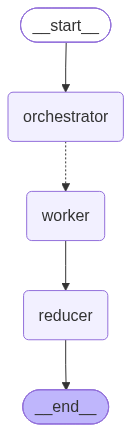

In [ ]:
app

In [ ]:
out = app.invoke({"topic": "Write a blog on Self Attention"})


HTTPStatusError: Error response 401 while fetching https://api.mistral.ai/v1/chat/completions: {"detail":"Your API key expired on 2026-10-16."}
